<a href="https://colab.research.google.com/github/DairoGit/chatbot-logbook-maestria/blob/main/Chatbot_Avance_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

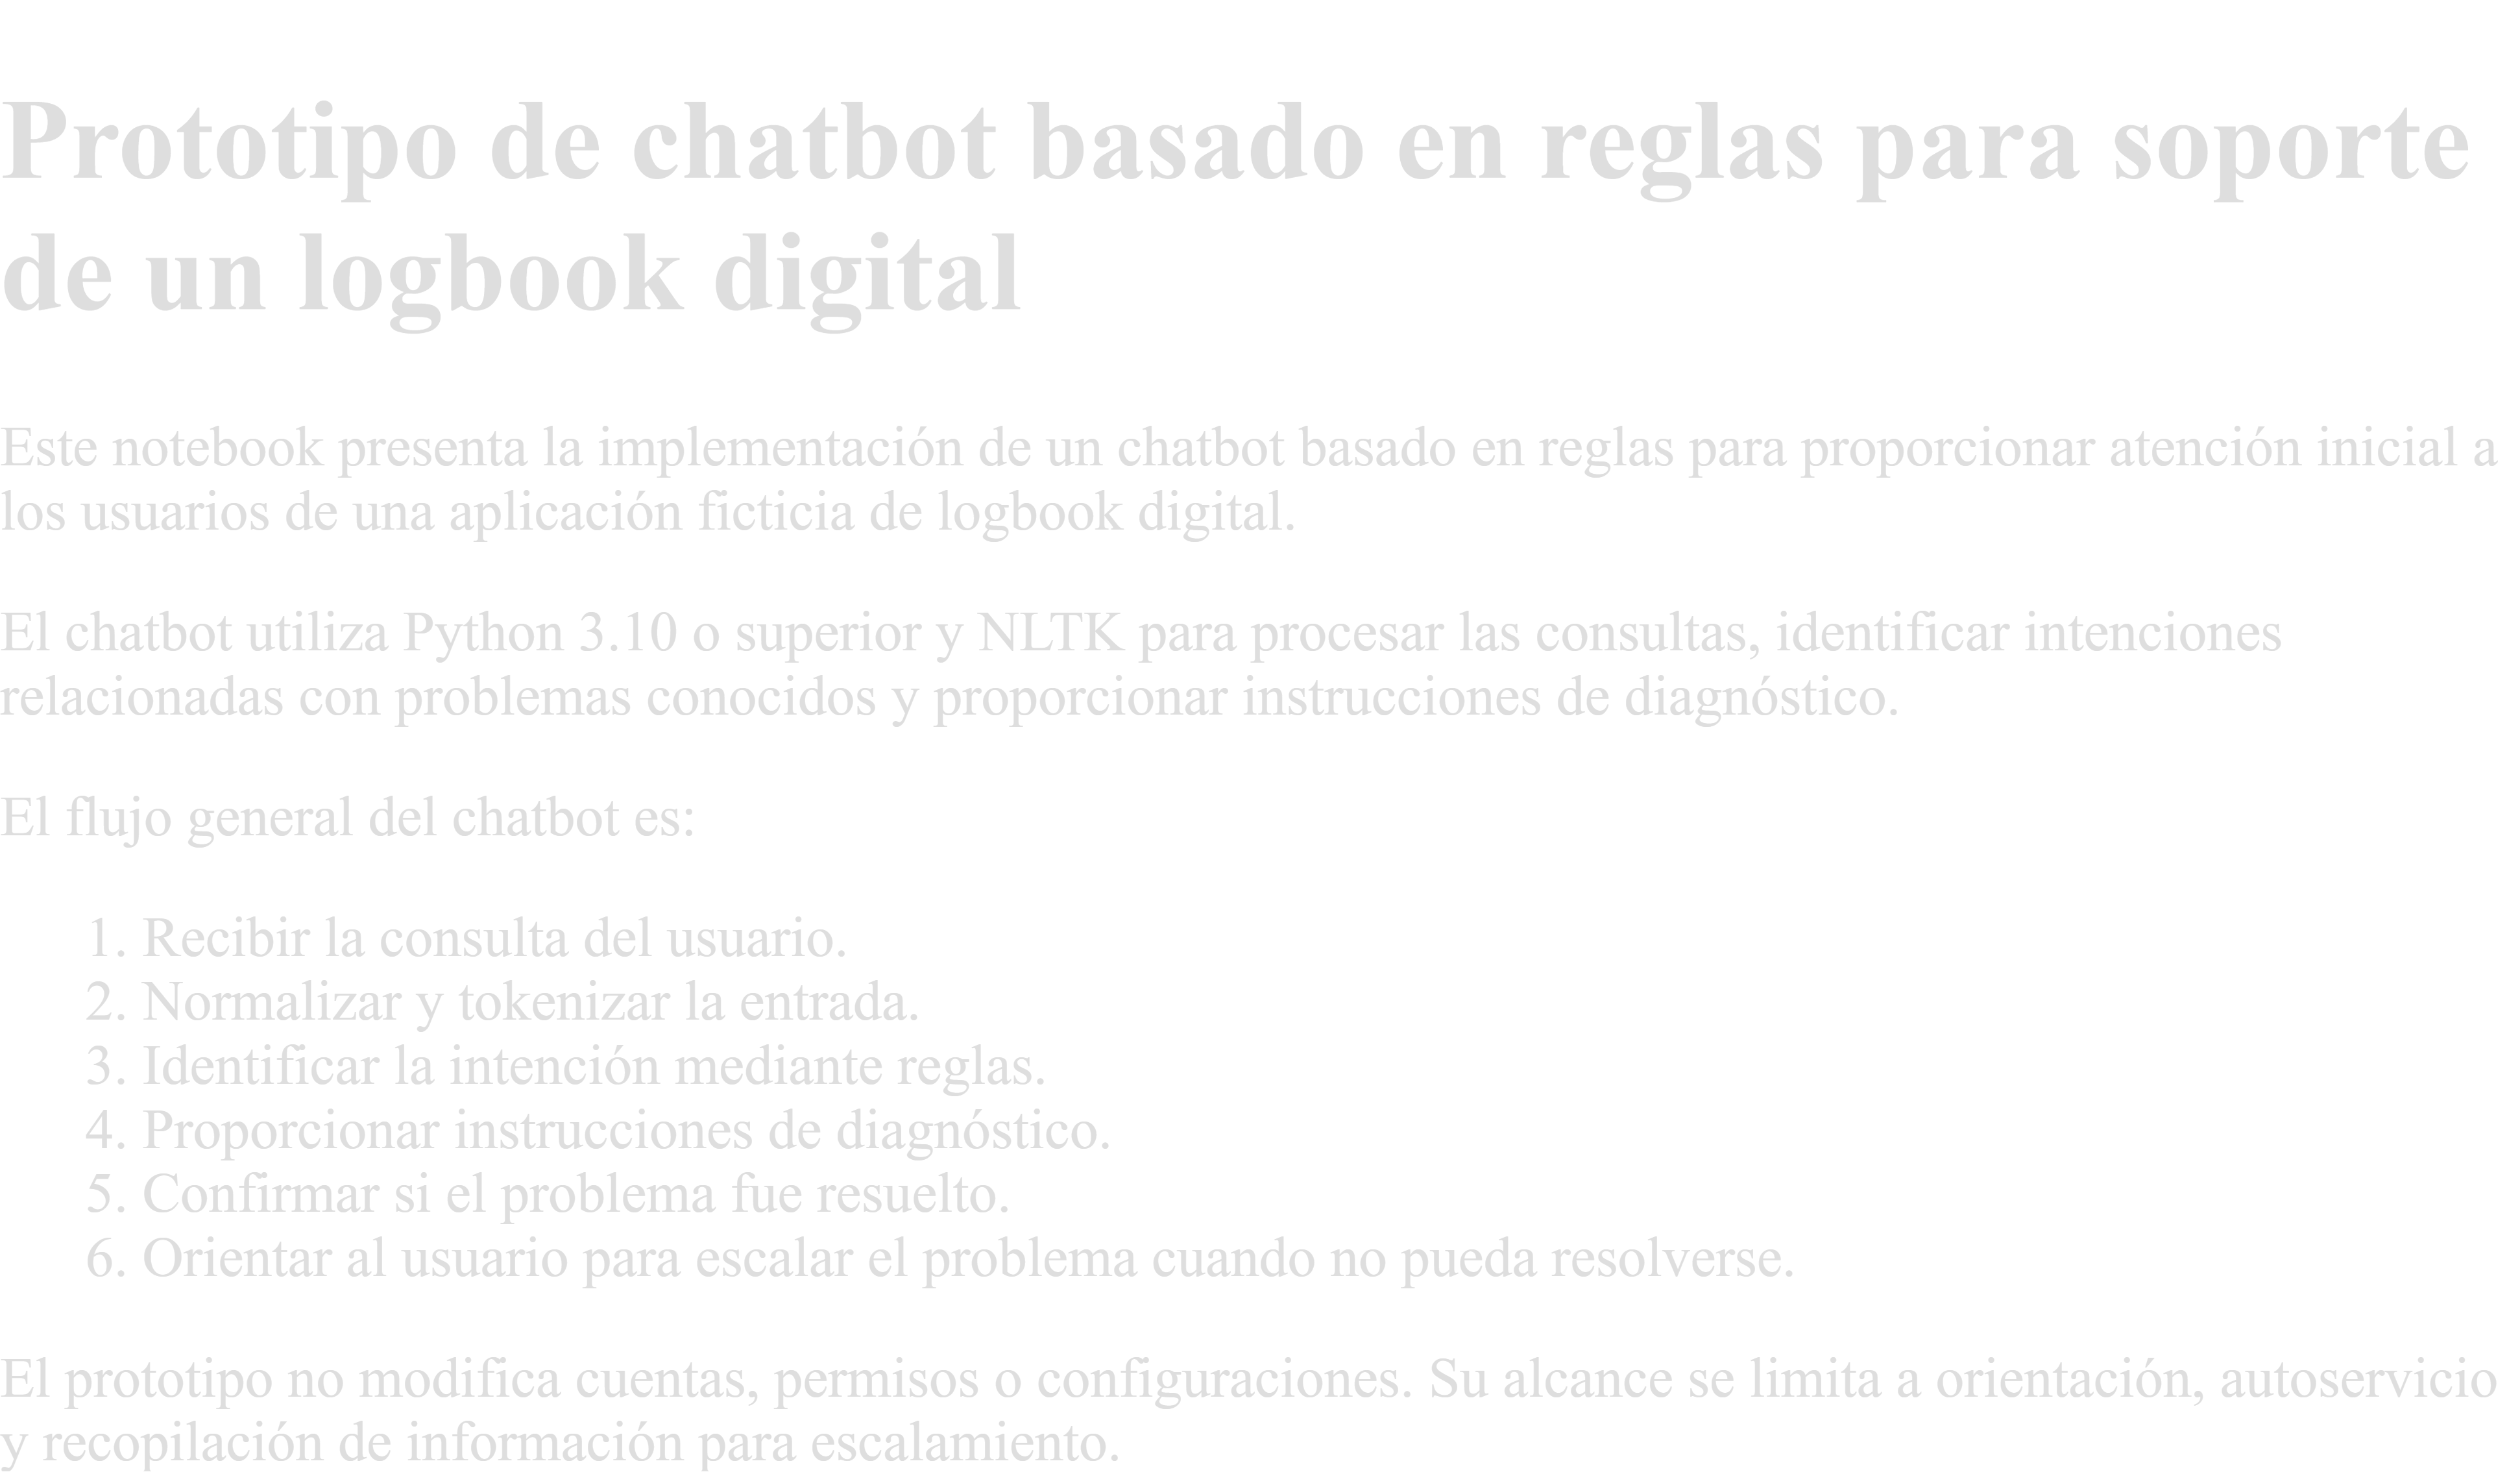

In [ ]:
import sys
import platform

version_python = sys.version_info

print("Versión completa:", sys.version)
print("Versión simplificada:",
      f"{version_python.major}.{version_python.minor}.{version_python.micro}")
print("Sistema:", platform.platform())

if version_python >= (3, 10):
    print("Resultado: se cumple el requisito de Python 3.10 o superior.")
else:
    raise RuntimeError(
        "El proyecto requiere Python 3.10 o superior."
    )

Versión completa: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Versión simplificada: 3.13.16
Sistema: Linux-6.6.122+-x86_64-with-glibc2.39
Resultado: se cumple el requisito de Python 3.10 o superior.


In [ ]:
!pip install -q nltk

import nltk

from nltk.tokenize import RegexpTokenizer
from nltk.stem.snowball import SpanishStemmer

print("Versión de NLTK:", nltk.__version__)
print("NLTK se importó correctamente.")


Versión de NLTK: 3.9.1
NLTK se importó correctamente.


In [ ]:
import re
import unicodedata

tokenizador = RegexpTokenizer(r"\w+")
stemmer = SpanishStemmer()


def eliminar_acentos(texto):
    """
    Elimina acentos para facilitar la comparación entre palabras.
    Ejemplo: 'sincronización' se convierte en 'sincronizacion'.
    """
    texto_normalizado = unicodedata.normalize("NFD", texto)

    return "".join(
        caracter
        for caracter in texto_normalizado
        if unicodedata.category(caracter) != "Mn"
    )


def normalizar_texto(texto):
    """
    Convierte la entrada en minúsculas, elimina acentos,
    tokeniza con NLTK y obtiene raíces mediante stemming.
    """
    if not isinstance(texto, str):
        return {
            "texto_original": "",
            "texto_normalizado": "",
            "tokens": [],
            "raices": []
        }

    texto_original = texto.strip()
    texto_limpio = eliminar_acentos(texto_original.lower())

    # Mantiene letras, números, espacios y algunos caracteres útiles.
    texto_limpio = re.sub(r"[^a-z0-9áéíóúüñ\s#%&._-]", " ", texto_limpio)
    texto_limpio = re.sub(r"\s+", " ", texto_limpio).strip()

    # Tokenización realizada mediante NLTK.
    tokens = tokenizador.tokenize(texto_limpio)

    # Stemming realizado mediante NLTK.
    raices = [stemmer.stem(token) for token in tokens]

    return {
        "texto_original": texto_original,
        "texto_normalizado": texto_limpio,
        "tokens": tokens,
        "raices": raices
    }

In [ ]:
ejemplo = "¡No puedo cargar mi archivo PDF con los resultados!"

resultado = normalizar_texto(ejemplo)

print("Texto original:")
print(resultado["texto_original"])

print("\nTexto normalizado:")
print(resultado["texto_normalizado"])

print("\nTokens generados por NLTK:")
print(resultado["tokens"])

print("\nRaíces generadas mediante stemming:")
print(resultado["raices"])

Texto original:
¡No puedo cargar mi archivo PDF con los resultados!

Texto normalizado:
no puedo cargar mi archivo pdf con los resultados

Tokens generados por NLTK:
['no', 'puedo', 'cargar', 'mi', 'archivo', 'pdf', 'con', 'los', 'resultados']

Raíces generadas mediante stemming:
['no', 'pued', 'carg', 'mi', 'archiv', 'pdf', 'con', 'los', 'result']


In [ ]:
BASE_CONOCIMIENTO = {
    "saludo": {
        "descripcion": "El usuario inicia la conversación.",
        "palabras_clave": [
            "hola", "buenas", "buenos", "saludos",
            "comenzar", "inicio"
        ],
        "frases": [
            "buenos dias",
            "buenas tardes",
            "buenas noches"
        ],
        "respuesta": (
            "Hola. Soy el asistente de soporte del logbook digital. "
            "Puedo ayudarte con problemas de carga de archivos, acceso, "
            "permisos, sincronización de cuentas, navegador y cuentas inactivas. "
            "Describe brevemente el problema que estás experimentando."
        )
    },

    "ayuda": {
        "descripcion": "El usuario solicita conocer las capacidades del chatbot.",
        "palabras_clave": [
            "ayuda", "opciones", "problemas", "soporte",
            "funciones", "puedes"
        ],
        "frases": [
            "en que puedes ayudar",
            "que problemas resuelves",
            "mostrar opciones"
        ],
        "respuesta": (
            "Puedo orientarte en las siguientes categorías:\n"
            "1. Problemas al cargar archivos PDF.\n"
            "2. Problemas de acceso o permisos.\n"
            "3. Cuentas nuevas pendientes de sincronización.\n"
            "4. Problemas de funcionamiento en el navegador.\n"
            "5. Cuentas desactivadas por inactividad.\n\n"
            "Describe el síntoma que observas para comenzar."
        )
    },

    "file_upload_issue": {
        "descripcion": "El usuario no puede cargar un archivo en el logbook.",
        "palabras_clave": [
            "archivo", "pdf", "cargar", "subir", "template",
            "plantilla", "resultados", "documento", "adjuntar"
        ],
        "frases": [
            "no puedo subir",
            "no puedo cargar",
            "error al subir archivo",
            "pdf no carga",
            "archivo rechazado",
            "enviar resultados"
        ],
        "respuesta": (
            "Identifiqué un posible problema de carga de archivos. "
            "Comencemos verificando el formato y el template."
        )
    },

    "access_permission_issue": {
        "descripcion": "El usuario no puede ingresar o carece de permisos.",
        "palabras_clave": [
            "acceso", "acceder", "permiso", "permisos",
            "autorizacion", "denegado", "ingresar", "entrar"
        ],
        "frases": [
            "no puedo acceder",
            "acceso denegado",
            "no tengo permisos",
            "sin autorizacion",
            "no puedo entrar"
        ],
        "respuesta": (
            "Identifiqué un posible problema de acceso o permisos. "
            "Necesito distinguir si la cuenta no permite iniciar sesión "
            "o si puedes ingresar, pero no puedes visualizar una función."
        )
    },

    "account_sync_issue": {
        "descripcion": "Una cuenta nueva todavía no se encuentra disponible.",
        "palabras_clave": [
            "sincronizar", "sincronizacion", "cuenta", "nueva",
            "creada", "directorio", "registrada", "provisionada"
        ],
        "frases": [
            "cuenta nueva",
            "cuenta no aparece",
            "usuario no sincronizado",
            "cuenta fue creada",
            "pendiente de sincronizacion"
        ],
        "respuesta": (
            "Identifiqué un posible problema de sincronización de cuenta. "
            "Primero verificaremos si la cuenta fue creada recientemente "
            "y todavía no está disponible en el logbook."
        )
    },

    "browser_issue": {
        "descripcion": "La aplicación presenta un comportamiento relacionado con el navegador.",
        "palabras_clave": [
            "navegador", "pagina", "carga", "cookies", "cache",
            "historial", "incognito", "pantalla", "sesion"
        ],
        "frases": [
            "pagina no carga",
            "pantalla en blanco",
            "aplicacion no responde",
            "se queda cargando",
            "modo incognito",
            "error del navegador"
        ],
        "respuesta": (
            "Identifiqué un posible problema relacionado con el navegador. "
            "Realizaremos una prueba en una sesión limpia para comprobar "
            "si el comportamiento está relacionado con datos almacenados localmente."
        )
    },

    "inactive_account_issue": {
        "descripcion": "La cuenta se encuentra inactiva o deshabilitada.",
        "palabras_clave": [
            "inactiva", "inactivo", "desactivada", "desactivado",
            "bloqueada", "bloqueado", "vacaciones", "ausencia"
        ],
        "frases": [
            "cuenta desactivada",
            "cuenta inactiva",
            "regrese de vacaciones",
            "usuario bloqueado",
            "tiempo sin usar"
        ],
        "respuesta": (
            "Identifiqué un posible problema de cuenta inactiva. "
            "La reactivación requiere validación e intervención autorizada."
        )
    },

    "agradecimiento": {
        "descripcion": "El usuario agradece la ayuda recibida.",
        "palabras_clave": [
            "gracias", "agradezco", "excelente", "perfecto"
        ],
        "frases": [
            "muchas gracias",
            "ya funciona",
            "problema resuelto"
        ],
        "respuesta": (
            "Me alegra haber sido de ayuda. "
            "Puedes realizar otra consulta o escribir 'salir' para finalizar."
        )
    },

    "despedida": {
        "descripcion": "El usuario desea terminar la conversación.",
        "palabras_clave": [
            "adios", "salir", "terminar", "finalizar",
            "chao", "bye"
        ],
        "frases": [
            "hasta luego",
            "finalizar conversacion",
            "quiero salir"
        ],
        "respuesta": (
            "La conversación ha finalizado. Gracias por utilizar "
            "el asistente del logbook digital."
        )
    }
}

In [ ]:
def preparar_reglas():
    """
    Genera versiones normalizadas de las palabras clave y frases
    definidas en la base de conocimiento.
    """
    reglas_preparadas = {}

    for nombre_intencion, datos in BASE_CONOCIMIENTO.items():
        raices_clave = set()

        for palabra in datos.get("palabras_clave", []):
            procesada = normalizar_texto(palabra)
            raices_clave.update(procesada["raices"])

        frases_normalizadas = []

        for frase in datos.get("frases", []):
            procesada = normalizar_texto(frase)
            frases_normalizadas.append(procesada["texto_normalizado"])

        reglas_preparadas[nombre_intencion] = {
            "raices_clave": raices_clave,
            "frases_normalizadas": frases_normalizadas
        }

    return reglas_preparadas


REGLAS_PREPARADAS = preparar_reglas()


def identificar_intencion(mensaje, mostrar_detalle=False):
    """
    Identifica la intención mediante coincidencias de frases
    y palabras clave normalizadas con NLTK.

    Puntuación:
    - Frase completa encontrada: 4 puntos.
    - Cada raíz/palabra clave coincidente: 1 punto.
    """
    procesamiento = normalizar_texto(mensaje)

    if not procesamiento["tokens"]:
        return {
            "intencion": "desconocida",
            "confianza": 0,
            "puntajes": {},
            "procesamiento": procesamiento
        }

    texto = procesamiento["texto_normalizado"]
    raices_entrada = set(procesamiento["raices"])

    puntajes = {}

    for intencion, reglas in REGLAS_PREPARADAS.items():
        puntuacion = 0

        for frase in reglas["frases_normalizadas"]:
            if frase and frase in texto:
                puntuacion += 4

        coincidencias = raices_entrada.intersection(
            reglas["raices_clave"]
        )

        puntuacion += len(coincidencias)
        puntajes[intencion] = puntuacion

    mejor_intencion = max(puntajes, key=puntajes.get)
    mejor_puntaje = puntajes[mejor_intencion]

    # Se exige un mínimo de dos puntos para evitar respuestas incorrectas.
    if mejor_puntaje < 2:
        mejor_intencion = "desconocida"

    resultado = {
        "intencion": mejor_intencion,
        "confianza": mejor_puntaje,
        "puntajes": puntajes,
        "procesamiento": procesamiento
    }

    if mostrar_detalle:
        print("Tokens:", procesamiento["tokens"])
        print("Raíces:", procesamiento["raices"])
        print("Puntajes:", puntajes)
        print("Intención seleccionada:", mejor_intencion)

    return resultado

In [ ]:
consultas_iniciales = [
    "No puedo subir mi archivo PDF con los resultados",
    "No tengo permisos para acceder al logbook",
    "Mi cuenta fue creada pero todavía no aparece",
    "La página se queda cargando y no responde",
    "Regresé de vacaciones y mi cuenta está desactivada"
]

for numero, consulta in enumerate(consultas_iniciales, start=1):
    resultado = identificar_intencion(consulta)

    print(f"\nPrueba {numero}")
    print("Entrada:", consulta)
    print("Intención:", resultado["intencion"])
    print("Puntuación:", resultado["confianza"])


Prueba 1
Entrada: No puedo subir mi archivo PDF con los resultados
Intención: file_upload_issue
Puntuación: 8

Prueba 2
Entrada: No tengo permisos para acceder al logbook
Intención: access_permission_issue
Puntuación: 6

Prueba 3
Entrada: Mi cuenta fue creada pero todavía no aparece
Intención: account_sync_issue
Puntuación: 6

Prueba 4
Entrada: La página se queda cargando y no responde
Intención: browser_issue
Puntuación: 6

Prueba 5
Entrada: Regresé de vacaciones y mi cuenta está desactivada
Intención: inactive_account_issue
Puntuación: 6


In [ ]:
FLUJOS = {
    "file_upload_issue": [
        {
            "pregunta": (
                "¿El archivo utiliza el template establecido y "
                "se encuentra en formato PDF? Responde 'sí' o 'no'."
            ),
            "si": "continuar",
            "no": (
                "Convierte el archivo a PDF y utiliza el template establecido. "
                "Después intenta cargarlo nuevamente."
            )
        },
        {
            "pregunta": (
                "¿El archivo tiene un tamaño igual o inferior a 10 MB? "
                "Responde 'sí' o 'no'."
            ),
            "si": "continuar",
            "no": (
                "Reduce el tamaño del archivo hasta 10 MB o menos "
                "e intenta cargarlo nuevamente."
            )
        },
        {
            "pregunta": (
                "¿El nombre del archivo evita los caracteres #, % y & "
                "y contiene 50 caracteres o menos? Responde 'sí' o 'no'."
            ),
            "si": "escalar",
            "no": (
                "Cambia el nombre del archivo, elimina los caracteres "
                "#, % y &, y utiliza un máximo de 50 caracteres. "
                "Después intenta cargarlo nuevamente."
            )
        }
    ],

    "access_permission_issue": [
        {
            "pregunta": (
                "¿Puedes iniciar sesión en el logbook? "
                "Responde 'sí' o 'no'."
            ),
            "si": "continuar",
            "no": (
                "Verifica que estés utilizando la cuenta asignada. "
                "Si la cuenta es correcta y el acceso continúa bloqueado, "
                "será necesario escalar el caso para validar su estado."
            )
        },
        {
            "pregunta": (
                "¿Puedes ingresar, pero no puedes visualizar una sección "
                "o ejecutar una función específica? Responde 'sí' o 'no'."
            ),
            "si": (
                "El comportamiento puede estar relacionado con permisos. "
                "Registra el nombre de la sección o función que no puedes usar "
                "para solicitar una validación de acceso."
            ),
            "no": "escalar"
        }
    ],

    "account_sync_issue": [
        {
            "pregunta": (
                "¿La cuenta fue creada recientemente? "
                "Responde 'sí' o 'no'."
            ),
            "si": "continuar",
            "no": "escalar"
        },
        {
            "pregunta": (
                "¿La cuenta ya aparece en el directorio de usuarios, "
                "pero todavía no aparece en el logbook? Responde 'sí' o 'no'."
            ),
            "si": (
                "El caso puede requerir una sincronización autorizada. "
                "Reúne el identificador de la cuenta y la evidencia de que "
                "ya está disponible en el directorio para solicitar soporte."
            ),
            "no": (
                "Primero debe validarse la creación de la cuenta en el "
                "directorio correspondiente antes de revisar su sincronización "
                "con el logbook."
            )
        }
    ],

    "browser_issue": [
        {
            "pregunta": (
                "¿La aplicación funciona correctamente al abrirla "
                "en una ventana privada o de incógnito? Responde 'sí' o 'no'."
            ),
            "si": (
                "El comportamiento parece estar relacionado con datos "
                "almacenados por el navegador. Cierra otras sesiones, limpia "
                "la caché y las cookies del sitio, abre nuevamente el navegador "
                "e intenta ingresar."
            ),
            "no": "continuar"
        },
        {
            "pregunta": (
                "¿El problema también ocurre en otro navegador compatible? "
                "Responde 'sí' o 'no'."
            ),
            "si": "escalar",
            "no": (
                "El comportamiento parece limitarse al navegador original. "
                "Utiliza temporalmente el navegador donde funciona y registra "
                "el nombre y versión del navegador afectado."
            )
        }
    ],

    "inactive_account_issue": [
        {
            "pregunta": (
                "¿El mensaje mostrado indica que la cuenta está "
                "inactiva, bloqueada o deshabilitada? Responde 'sí' o 'no'."
            ),
            "si": (
                "La reactivación requiere intervención autorizada. "
                "Reúne el identificador de la cuenta y una captura del mensaje "
                "mostrado para solicitar la validación y reactivación."
            ),
            "no": "escalar"
        }
    ]
}

In [ ]:
RESPUESTAS_AFIRMATIVAS = {
    "si", "correcto", "afirmativo", "claro",
    "cumple", "funciona", "resuelto"
}

RESPUESTAS_NEGATIVAS = {
    "no", "negativo", "incorrecto", "continua",
    "persiste", "sigue", "falla"
}


def interpretar_confirmacion(mensaje):
    """
    Clasifica respuestas breves como afirmativas, negativas
    o no reconocidas.
    """
    datos = normalizar_texto(mensaje)
    tokens = set(datos["tokens"])

    if tokens.intersection(RESPUESTAS_AFIRMATIVAS):
        return True

    if tokens.intersection(RESPUESTAS_NEGATIVAS):
        return False

    return None

In [ ]:
def mensaje_escalamiento(intencion):
    """
    Devuelve los datos que el usuario debe reunir cuando el chatbot
    no puede resolver el problema.
    """
    datos_especificos = {
        "file_upload_issue": [
            "nombre del archivo",
            "formato del archivo",
            "tamaño del archivo",
            "mensaje de error",
            "pasos realizados antes del error"
        ],

        "access_permission_issue": [
            "identificador de la cuenta",
            "sección o función que no puede utilizar",
            "mensaje de acceso denegado",
            "fecha aproximada en que comenzó el problema"
        ],

        "account_sync_issue": [
            "identificador de la cuenta",
            "fecha aproximada de creación",
            "confirmación de que la cuenta existe en el directorio",
            "captura o mensaje mostrado en el logbook"
        ],

        "browser_issue": [
            "navegador utilizado",
            "versión del navegador",
            "mensaje de error",
            "resultado de la prueba en modo incógnito",
            "resultado de la prueba en otro navegador"
        ],

        "inactive_account_issue": [
            "identificador de la cuenta",
            "mensaje mostrado",
            "fecha aproximada del último acceso",
            "captura del error"
        ],

        "desconocida": [
            "descripción detallada del problema",
            "acción que intentabas realizar",
            "mensaje de error",
            "momento aproximado en que ocurrió",
            "captura de pantalla, si está disponible"
        ]
    }

    elementos = datos_especificos.get(
        intencion,
        datos_especificos["desconocida"]
    )

    lista = "\n".join(
        f"- {elemento}" for elemento in elementos
    )

    return (
        "No pude resolver el problema mediante las verificaciones "
        "disponibles. Para solicitar soporte, reúne la siguiente "
        f"información:\n{lista}\n\n"
        "Incluye también las acciones de troubleshooting que ya realizaste."
    )

In [ ]:
class ChatbotLogbook:
    """
    Chatbot basado en reglas para soporte inicial
    de una aplicación ficticia de logbook.
    """

    def __init__(self):
        self.reiniciar()

    def reiniciar(self):
        self.intencion_activa = None
        self.paso_actual = 0
        self.conversacion_activa = True

    def obtener_estado(self):
        return {
            "intencion_activa": self.intencion_activa,
            "paso_actual": self.paso_actual,
            "conversacion_activa": self.conversacion_activa
        }

    def responder(self, mensaje):
        if not isinstance(mensaje, str) or not mensaje.strip():
            return (
                "No recibí una consulta válida. Describe brevemente "
                "el problema que estás experimentando."
            )

        # Si existe un diagnóstico en curso, continuar con ese flujo.
        if self.intencion_activa is not None:
            return self._continuar_flujo(mensaje)

        resultado = identificar_intencion(mensaje)
        intencion = resultado["intencion"]

        if intencion == "desconocida":
            return mensaje_escalamiento("desconocida")

        if intencion == "despedida":
            self.conversacion_activa = False
            return BASE_CONOCIMIENTO[intencion]["respuesta"]

        respuesta_inicial = BASE_CONOCIMIENTO[intencion]["respuesta"]

        # Intenciones auxiliares que no necesitan troubleshooting.
        if intencion in {
            "saludo",
            "ayuda",
            "agradecimiento"
        }:
            return respuesta_inicial

        # Inicio de flujo diagnóstico.
        if intencion in FLUJOS:
            self.intencion_activa = intencion
            self.paso_actual = 0

            primera_pregunta = FLUJOS[intencion][0]["pregunta"]

            return (
                f"{respuesta_inicial}\n\n"
                f"{primera_pregunta}"
            )

        return respuesta_inicial

    def _continuar_flujo(self, mensaje):
        confirmacion = interpretar_confirmacion(mensaje)

        if confirmacion is None:
            return (
                "No pude interpretar la respuesta. "
                "Responde únicamente 'sí' o 'no' para continuar."
            )

        flujo = FLUJOS[self.intencion_activa]
        paso = flujo[self.paso_actual]
        accion = paso["si"] if confirmacion else paso["no"]

        if accion == "continuar":
            self.paso_actual += 1

            if self.paso_actual >= len(flujo):
                intencion_anterior = self.intencion_activa
                self.intencion_activa = None
                self.paso_actual = 0
                return mensaje_escalamiento(intencion_anterior)

            return flujo[self.paso_actual]["pregunta"]

        if accion == "escalar":
            intencion_anterior = self.intencion_activa
            self.intencion_activa = None
            self.paso_actual = 0

            return mensaje_escalamiento(intencion_anterior)

        # La acción contiene una recomendación o conclusión.
        self.intencion_activa = None
        self.paso_actual = 0

        return (
            f"{accion}\n\n"
            "Después de realizar la acción, puedes iniciar una nueva "
            "consulta e indicar si el problema persiste."
        )

In [ ]:
def iniciar_chat():
    bot = ChatbotLogbook()

    print("=" * 70)
    print("ASISTENTE DE SOPORTE DEL LOGBOOK DIGITAL")
    print("=" * 70)
    print(
        "Describe tu problema. Escribe 'ayuda' para conocer las opciones "
        "o 'salir' para finalizar.\n"
    )

    while bot.conversacion_activa:
        try:
            mensaje_usuario = input("Usuario: ").strip()
        except (EOFError, KeyboardInterrupt):
            print("\nChatbot: Conversación finalizada.")
            break

        # Elimina comillas accidentales y normaliza el comando
        comando = mensaje_usuario.lower().strip().strip("'\"")

        # Evitar entradas vacías
        if not comando:
            print("\nChatbot: Por favor, describe tu problema.\n")
            continue

        # Comando de ayuda
        if comando == "ayuda":
            print(
                "\nChatbot: Puedo orientarte con los siguientes problemas:\n"
                "- permisos o acceso al logbook\n"
                "- sincronización de una cuenta nueva\n"
                "- problemas de carga relacionados con el navegador\n"
                "- cuenta inactiva\n"
                "- problemas para cargar archivos\n"
                "\nDescribe el problema con tus propias palabras."
                "\nEscribe 'salir' para finalizar.\n"
            )
            continue

        # Comando de salida
        if comando in {"salir", "adios", "adiós", "terminar", "finalizar"}:
            bot.conversacion_activa = False
            print(
                "\nChatbot: La conversación ha finalizado. "
                "Gracias por utilizar el asistente del logbook digital.\n"
            )
            break

        # Cualquier otro mensaje se procesa normalmente
        respuesta = bot.responder(mensaje_usuario)
        print(f"\nChatbot: {respuesta}\n")

    return bot

In [36]:
chatbot = iniciar_chat()

ASISTENTE DE SOPORTE DEL LOGBOOK DIGITAL
Describe tu problema. Escribe 'ayuda' para conocer las opciones o 'salir' para finalizar.


Chatbot: No pude resolver el problema mediante las verificaciones disponibles. Para solicitar soporte, reúne la siguiente información:
- descripción detallada del problema
- acción que intentabas realizar
- mensaje de error
- momento aproximado en que ocurrió
- captura de pantalla, si está disponible

Incluye también las acciones de troubleshooting que ya realizaste.


Chatbot: Conversación finalizada.
